
楕円曲線ECDH 詳細計算プログラム
曲線: y^2 = x^3 + 2x + 2 mod 17
基準点 G = (5, 1)
詳細表示 = True

----------------------------------------------------------------------
基準点の確認
----------------------------------------------------------------------
点 (5, 1) の曲線判定
  左辺: y^2 mod 17 = 1^2 mod 17 = 1
  右辺: x^3 + 2x + 2 mod 17
       = 5^3 + 2×5 + 2 mod 17
       = 1
  判定: 1 = 1 → True

基準点Gの位数 = 19

----------------------------------------------------------------------
倍点表の作成
----------------------------------------------------------------------

----------------------------------------------------------------------
1Gの計算
----------------------------------------------------------------------

点の加算を開始
計算内容: 1G = 0G + G
  P1 = O
  P2 = (5, 1)
  P1は無限遠点Oです。
  O + P2 = P2 = (5, 1)
 1G = (5, 1)

----------------------------------------------------------------------
2Gの計算
----------------------------------------------------------------------

点の加算を開始
計算内容: 2G = 1G + G
  P1 = (5, 1)
  P2 = (5, 1)
  種類: 倍点計算

傾きの分子
  3

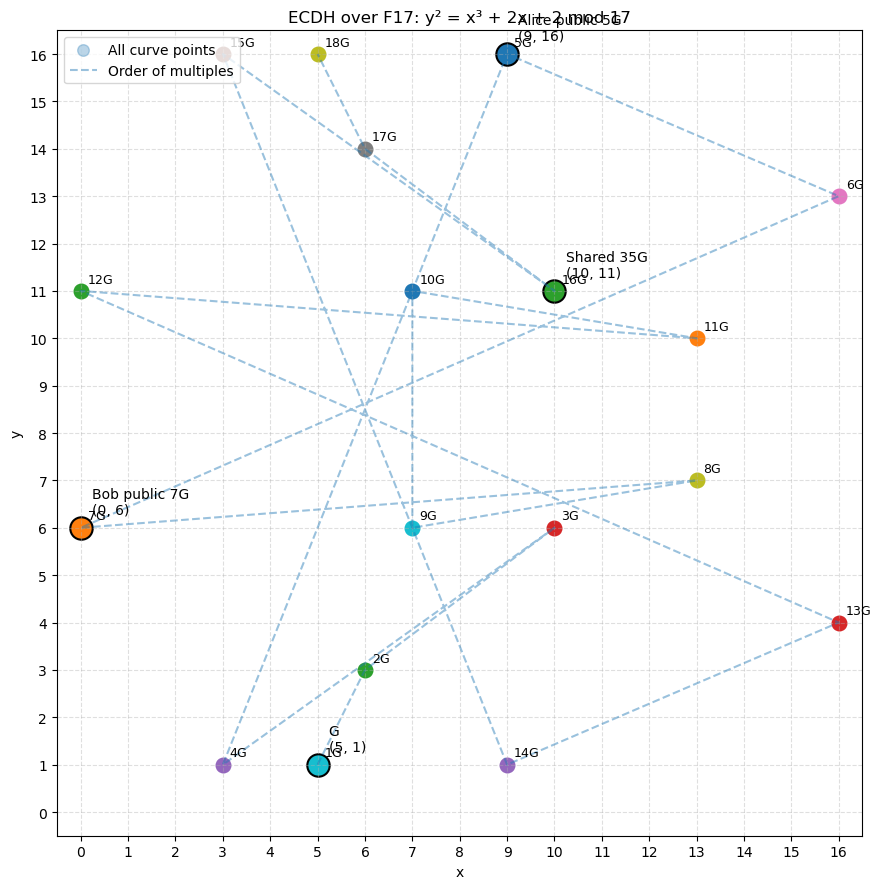


プロットを保存しました: ecdh_detailed_plot.png


In [1]:
# ============================================================
# 楕円曲線暗号 ECDH 学習用プログラム
# 詳細な途中経過表示・倍点表・プロット付き
#
# 曲線:
#   y^2 = x^3 + ax + b (mod p)
#
# 設定:
#   p = 17
#   a = 2
#   b = 2
#   G = (5, 1)
#
# Alice:
#   秘密鍵 5
#
# Bob:
#   秘密鍵 7
# ============================================================

from typing import Optional, Tuple, List
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 型と楕円曲線の設定
# ------------------------------------------------------------

Point = Optional[Tuple[int, int]]

P = 17
A = 2
B = 2

G: Point = (5, 1)

# Trueにすると詳細な途中経過を表示する
SHOW_DETAILS = True


# ------------------------------------------------------------
# 表示用関数
# ------------------------------------------------------------

def point_text(point: Point) -> str:
    """
    点を表示用の文字列に変換する。
    """
    if point is None:
        return "O"
    return str(point)


def section(title: str) -> None:
    """
    見出しを表示する。
    """
    print()
    print("=" * 70)
    print(title)
    print("=" * 70)


def subsection(title: str) -> None:
    """
    小見出しを表示する。
    """
    print()
    print("-" * 70)
    print(title)
    print("-" * 70)


# ------------------------------------------------------------
# 逆元
# ------------------------------------------------------------

def mod_inverse(
    value: int,
    modulus: int,
    verbose: bool = False
) -> int:
    """
    value の modulus における逆元を求める。

    value × inverse ≡ 1 mod modulus
    """

    original_value = value
    value %= modulus

    if value == 0:
        raise ZeroDivisionError("0の逆元は存在しません。")

    inverse = pow(value, -1, modulus)

    if verbose:
        print("逆元の計算")
        print(
            f"  {original_value} mod {modulus}"
            f" = {value}"
        )
        print(
            f"  {value}^(-1) mod {modulus}"
            f" = {inverse}"
        )
        print(
            f"  確認: {value} × {inverse}"
            f" = {value * inverse}"
            f" ≡ {(value * inverse) % modulus}"
            f" mod {modulus}"
        )

    return inverse


# ------------------------------------------------------------
# 曲線上の点か確認
# ------------------------------------------------------------

def is_on_curve(
    point: Point,
    verbose: bool = False
) -> bool:
    """
    点が楕円曲線上にあるか確認する。
    """

    if point is None:
        if verbose:
            print("Oは無限遠点なので曲線上の点として扱います。")
        return True

    x, y = point

    left = (y * y) % P
    right = (x**3 + A * x + B) % P

    result = left == right

    if verbose:
        print(f"点 {point} の曲線判定")
        print(
            f"  左辺: y^2 mod {P}"
            f" = {y}^2 mod {P}"
            f" = {left}"
        )
        print(
            f"  右辺: x^3 + {A}x + {B} mod {P}"
        )
        print(
            f"       = {x}^3 + {A}×{x} + {B}"
            f" mod {P}"
        )
        print(f"       = {right}")
        print(f"  判定: {left} = {right} → {result}")

    return result


# ------------------------------------------------------------
# 点の逆元
# ------------------------------------------------------------

def point_neg(point: Point) -> Point:
    """
    楕円曲線上の点の逆元を返す。

    -(x, y) = (x, -y mod p)
    """

    if point is None:
        return None

    x, y = point
    return x, (-y) % P


# ------------------------------------------------------------
# 点の加算
# ------------------------------------------------------------

def point_add(
    point1: Point,
    point2: Point,
    verbose: bool = False,
    label: str = ""
) -> Point:
    """
    楕円曲線上の点 point1 と point2 を加算する。

    異なる点:
        λ = (y2-y1)(x2-x1)^(-1) mod p

    同じ点:
        λ = (3x1^2+a)(2y1)^(-1) mod p
    """

    if verbose:
        print()
        print("点の加算を開始")
        if label:
            print(f"計算内容: {label}")
        print(f"  P1 = {point_text(point1)}")
        print(f"  P2 = {point_text(point2)}")

    # O + Q = Q
    if point1 is None:
        if verbose:
            print("  P1は無限遠点Oです。")
            print(f"  O + P2 = P2 = {point_text(point2)}")
        return point2

    # P + O = P
    if point2 is None:
        if verbose:
            print("  P2は無限遠点Oです。")
            print(f"  P1 + O = P1 = {point_text(point1)}")
        return point1

    x1, y1 = point1
    x2, y2 = point2

    # P + (-P) = O
    if x1 == x2 and (y1 + y2) % P == 0:
        if verbose:
            print("  2点は互いに逆元です。")
            print(
                f"  x1 = x2 = {x1}"
            )
            print(
                f"  y1 + y2 = {y1} + {y2}"
                f" = {y1 + y2}"
            )
            print(
                f"  {y1 + y2} mod {P}"
                f" = {(y1 + y2) % P}"
            )
            print("  よって P1 + P2 = O")
        return None

    # 同じ点なら倍点
    if point1 == point2:
        calculation_type = "倍点計算"

        numerator_raw = 3 * x1 * x1 + A
        denominator_raw = 2 * y1

        numerator = numerator_raw % P
        denominator = denominator_raw % P

        if verbose:
            print(f"  種類: {calculation_type}")
            print()
            print("傾きの分子")
            print(
                f"  3x1^2 + a"
                f" = 3×{x1}^2 + {A}"
            )
            print(
                f"             = {numerator_raw}"
            )
            print(
                f"             ≡ {numerator}"
                f" mod {P}"
            )

            print()
            print("傾きの分母")
            print(
                f"  2y1 = 2×{y1}"
                f" = {denominator_raw}"
            )
            print(
                f"      ≡ {denominator}"
                f" mod {P}"
            )

    # 異なる点なら通常の加算
    else:
        calculation_type = "異なる2点の加算"

        numerator_raw = y2 - y1
        denominator_raw = x2 - x1

        numerator = numerator_raw % P
        denominator = denominator_raw % P

        if verbose:
            print(f"  種類: {calculation_type}")

            print()
            print("傾きの分子")
            print(
                f"  y2 - y1"
                f" = {y2} - {y1}"
                f" = {numerator_raw}"
            )
            print(
                f"  {numerator_raw} mod {P}"
                f" = {numerator}"
            )

            print()
            print("傾きの分母")
            print(
                f"  x2 - x1"
                f" = {x2} - {x1}"
                f" = {denominator_raw}"
            )
            print(
                f"  {denominator_raw} mod {P}"
                f" = {denominator}"
            )

    # 分母の逆元
    inverse = mod_inverse(
        denominator,
        P,
        verbose=verbose
    )

    # 傾き
    slope_raw = numerator * inverse
    slope = slope_raw % P

    if verbose:
        print()
        print("傾き λ の計算")
        print(
            f"  λ = 分子 × 分母の逆元 mod {P}"
        )
        print(
            f"    = {numerator} × {inverse}"
            f" mod {P}"
        )
        print(
            f"    = {slope_raw} mod {P}"
        )
        print(f"    = {slope}")

    # x3
    x3_raw = slope * slope - x1 - x2
    x3 = x3_raw % P

    if verbose:
        print()
        print("x3の計算")
        print(
            f"  x3 = λ^2 - x1 - x2 mod {P}"
        )
        print(
            f"     = {slope}^2 - {x1} - {x2}"
            f" mod {P}"
        )
        print(
            f"     = {x3_raw} mod {P}"
        )
        print(f"     = {x3}")

    # y3
    y3_raw = slope * (x1 - x3) - y1
    y3 = y3_raw % P

    if verbose:
        print()
        print("y3の計算")
        print(
            f"  y3 = λ(x1-x3)-y1 mod {P}"
        )
        print(
            f"     = {slope}×({x1}-{x3})-{y1}"
            f" mod {P}"
        )
        print(
            f"     = {y3_raw} mod {P}"
        )
        print(f"     = {y3}")

    result = x3, y3

    if not is_on_curve(result):
        raise ValueError(
            f"計算結果 {result} は曲線上にありません。"
        )

    if verbose:
        print()
        print(
            f"計算結果: "
            f"{point_text(point1)} + "
            f"{point_text(point2)} = "
            f"{result}"
        )

        print()
        print("結果の曲線判定")
        is_on_curve(result, verbose=True)

    return result


# ------------------------------------------------------------
# スカラー倍算
# ------------------------------------------------------------

def scalar_multiply(
    k: int,
    point: Point,
    verbose: bool = False,
    name: str = ""
) -> Point:
    """
    kPを二進法の倍加加算法で計算する。

    例:
        13 = 1101₂
        13P = 8P + 4P + P
    """

    if k < 0:
        raise ValueError("負のスカラーには対応していません。")

    if verbose:
        subsection(
            name if name else
            f"{k} × {point_text(point)} の計算"
        )

        print(f"整数 k = {k}")
        print(f"2進数   = {k:b}")
        print(f"基準点   = {point_text(point)}")
        print()
        print("倍加加算法を開始します。")
        print(
            "resultは現在までの答え、"
            "addendは現在の点の重みです。"
        )

    original_k = k
    result: Point = None
    addend = point
    step = 1

    while k > 0:
        bit = k & 1

        if verbose:
            print()
            print("#" * 70)
            print(f"ステップ {step}")
            print("#" * 70)
            print(f"現在の k       = {k}")
            print(f"現在の2進数    = {k:b}")
            print(f"最下位ビット   = {bit}")
            print(
                f"現在の result  = {point_text(result)}"
            )
            print(
                f"現在の addend  = {point_text(addend)}"
            )

        # ビットが1ならresultに加算
        if bit == 1:
            if verbose:
                print()
                print(
                    "最下位ビットが1なので、"
                    "resultにaddendを加えます。"
                )

            result = point_add(
                result,
                addend,
                verbose=verbose,
                label=(
                    f"result + addend "
                    f"（{original_k}倍算の加算処理）"
                )
            )

            if verbose:
                print()
                print(
                    "加算後の result"
                    f" = {point_text(result)}"
                )

        else:
            if verbose:
                print()
                print(
                    "最下位ビットが0なので、"
                    "resultへの加算は行いません。"
                )

        # addendを倍点
        if verbose:
            print()
            print("次のビット用にaddendを2倍します。")

        addend = point_add(
            addend,
            addend,
            verbose=verbose,
            label="addendの倍点"
        )

        if verbose:
            print()
            print(
                "倍点後の addend"
                f" = {point_text(addend)}"
            )

        # kを右シフト
        old_k = k
        k >>= 1

        if verbose:
            print()
            print("kを右に1ビットシフトします。")
            print(
                f"  {old_k} ({old_k:b}₂)"
                f" → {k} ({k:b}₂)"
            )

        step += 1

    if verbose:
        print()
        print("*" * 70)
        print(
            f"最終結果: {original_k}"
            f" × {point_text(point)}"
            f" = {point_text(result)}"
        )
        print("*" * 70)

    return result


# ------------------------------------------------------------
# 曲線上の全点
# ------------------------------------------------------------

def curve_points() -> List[Tuple[int, int]]:
    """
    有限体上の楕円曲線の全有限点を列挙する。
    """

    points: List[Tuple[int, int]] = []

    for x in range(P):
        rhs = (x**3 + A * x + B) % P

        for y in range(P):
            lhs = (y * y) % P

            if lhs == rhs:
                points.append((x, y))

    return points


# ------------------------------------------------------------
# 点の位数
# ------------------------------------------------------------

def point_order(
    point: Point,
    max_search: int = 1000
) -> int:
    """
    点の位数を求める。
    """

    current: Point = None

    for k in range(1, max_search + 1):
        current = point_add(current, point)

        if current is None:
            return k

    raise ValueError(
        f"位数が{max_search}以内で見つかりません。"
    )


# ------------------------------------------------------------
# 逐次加算による倍点表
# ------------------------------------------------------------

def print_multiple_table(
    point: Point,
    order: int,
    detailed_until: int = 4
) -> List[Point]:
    """
    G、2G、3G、...を逐次加算で求める。

    detailed_untilまでの計算は途中経過を表示する。
    """

    subsection("倍点表の作成")

    results: List[Point] = []
    current: Point = None

    for k in range(1, order + 1):
        verbose = SHOW_DETAILS and k <= detailed_until

        if verbose:
            subsection(
                f"{k}Gの計算"
            )

        current = point_add(
            current,
            point,
            verbose=verbose,
            label=f"{k}G = {(k - 1)}G + G"
        )

        results.append(current)

        print(
            f"{k:2d}G = {point_text(current)}"
        )

    return results


# ------------------------------------------------------------
# プロット
# ------------------------------------------------------------

def plot_curve_and_multiples(
    base_point: Point,
    multiples: List[Point],
    alice_public: Point,
    bob_public: Point,
    shared_point: Point,
    save_path: str = "ecdh_detailed_plot.png"
) -> None:
    """
    楕円曲線上の全点と倍点をプロットする。
    """

    all_points = curve_points()

    fig, ax = plt.subplots(figsize=(11, 9))

    # 曲線上の全有限点
    xs_all = [point[0] for point in all_points]
    ys_all = [point[1] for point in all_points]

    ax.scatter(
        xs_all,
        ys_all,
        s=70,
        alpha=0.30,
        label="All curve points"
    )

    # 倍点を順番に結ぶ
    finite_multiples = [
        point for point in multiples
        if point is not None
    ]

    xs_multiple = [
        point[0] for point in finite_multiples
    ]
    ys_multiple = [
        point[1] for point in finite_multiples
    ]

    ax.plot(
        xs_multiple,
        ys_multiple,
        linestyle="--",
        alpha=0.45,
        label="Order of multiples"
    )

    # 各倍点
    for k, point in enumerate(multiples, start=1):
        if point is None:
            continue

        x, y = point

        ax.scatter(
            x,
            y,
            s=110
        )

        ax.annotate(
            f"{k}G",
            xy=(x, y),
            xytext=(5, 6),
            textcoords="offset points",
            fontsize=9
        )

    # 特別な点
    special_points = [
        ("G", base_point),
        ("Alice public 5G", alice_public),
        ("Bob public 7G", bob_public),
        ("Shared 35G", shared_point),
    ]

    for label, point in special_points:
        if point is None:
            continue

        x, y = point

        ax.scatter(
            x,
            y,
            s=260,
            edgecolors="black",
            linewidths=1.5
        )

        ax.annotate(
            f"{label}\n{point}",
            xy=(x, y),
            xytext=(8, 10),
            textcoords="offset points",
            fontsize=10
        )

    ax.set_title(
        "ECDH over F17: "
        "y² = x³ + 2x + 2 mod 17"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    ax.set_xticks(range(P))
    ax.set_yticks(range(P))

    ax.set_xlim(-0.5, P - 0.5)
    ax.set_ylim(-0.5, P - 0.5)

    ax.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.legend(loc="upper left")

    fig.tight_layout()
    fig.savefig(
        save_path,
        dpi=180
    )
    plt.show()

    print()
    print(
        f"プロットを保存しました: {save_path}"
    )


# ------------------------------------------------------------
# メイン処理
# ------------------------------------------------------------

def main() -> None:
    section("楕円曲線ECDH 詳細計算プログラム")

    print(
        f"曲線: y^2 = x^3 + {A}x + {B}"
        f" mod {P}"
    )
    print(f"基準点 G = {G}")
    print(
        f"詳細表示 = {SHOW_DETAILS}"
    )

    subsection("基準点の確認")

    if not is_on_curve(G, verbose=True):
        raise ValueError(
            "基準点Gは楕円曲線上にありません。"
        )

    order = point_order(G)

    print()
    print(f"基準点Gの位数 = {order}")

    # 倍点表
    # 1Gから4Gまでは途中経過を詳しく表示
    multiples = print_multiple_table(
        G,
        order,
        detailed_until=4
    )

    # 秘密鍵
    alice_private = 5
    bob_private = 7

    section("Aliceの公開鍵の計算")

    alice_public = scalar_multiply(
        alice_private,
        G,
        verbose=SHOW_DETAILS,
        name=(
            "Aliceの公開鍵 "
            "QA = 5G の途中経過"
        )
    )

    print()
    print(
        f"Aliceの秘密鍵 dA"
        f" = {alice_private}"
    )
    print(
        f"Aliceの公開鍵 QA"
        f" = {point_text(alice_public)}"
    )

    section("Bobの公開鍵の計算")

    bob_public = scalar_multiply(
        bob_private,
        G,
        verbose=SHOW_DETAILS,
        name=(
            "Bobの公開鍵 "
            "QB = 7G の途中経過"
        )
    )

    print()
    print(
        f"Bobの秘密鍵 dB"
        f" = {bob_private}"
    )
    print(
        f"Bobの公開鍵 QB"
        f" = {point_text(bob_public)}"
    )

    section("Aliceが共有点を計算")

    alice_shared = scalar_multiply(
        alice_private,
        bob_public,
        verbose=SHOW_DETAILS,
        name=(
            "Aliceの共有点 "
            "SA = dA × QB = 5 × QB"
        )
    )

    section("Bobが共有点を計算")

    bob_shared = scalar_multiply(
        bob_private,
        alice_public,
        verbose=SHOW_DETAILS,
        name=(
            "Bobの共有点 "
            "SB = dB × QA = 7 × QA"
        )
    )

    section("ECDHの最終結果")

    print(
        f"Aliceの公開鍵:"
        f" {point_text(alice_public)}"
    )
    print(
        f"Bobの公開鍵:"
        f"   {point_text(bob_public)}"
    )
    print()
    print(
        f"Aliceが計算した共有点:"
        f" {point_text(alice_shared)}"
    )
    print(
        f"Bobが計算した共有点:"
        f"   {point_text(bob_shared)}"
    )

    if alice_shared == bob_shared:
        print()
        print("共有点は一致しました。")

        if alice_shared is not None:
            shared_x, shared_y = alice_shared

            print(
                f"共有点 S = ({shared_x}, {shared_y})"
            )
            print(
                f"共有点のx座標 = {shared_x}"
            )
            print(
                f"共有点のy座標 = {shared_y}"
            )
    else:
        print()
        print("エラー: 共有点が一致しません。")

    # プロット
    section("プロットの作成")

    plot_curve_and_multiples(
        base_point=G,
        multiples=multiples[:-1],
        alice_public=alice_public,
        bob_public=bob_public,
        shared_point=alice_shared,
        save_path="ecdh_detailed_plot.png"
    )


if __name__ == "__main__":
    main()